In [2]:
import os
import numpy as np
import scipy.io as sio
from tqdm import tqdm
import h5py

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"

import sys
sys.path.append("..") 

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [3]:
from processing import  load_UCI_dataset, plot_regression_results, print_metrics, plot_convtran_loss
from UCI.pre_processing import  create_dataloaders

In [4]:
BASE_DIR = "/data1/yashvi_bhuva/BP_estimation_using_PPG/VitalDB/ML/non_fiducial_features/5sec_50%overlap/vitaldb_checkpoints"
X_train, y_train, X_val, y_val, X_test, y_test = load_UCI_dataset(WINDOW_SIZE= 625, STEP_SIZE= 312)

Total recordings: 12000
Train recordings: 9600
Validation recordings: 1200
Test recordings: 1200


100%|██████████| 9600/9600 [03:05<00:00, 51.85it/s]


Skipped recordings: 81


100%|██████████| 1200/1200 [00:22<00:00, 53.63it/s]


Skipped recordings: 7


100%|██████████| 1200/1200 [00:24<00:00, 49.74it/s]


Skipped recordings: 9


In [5]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# The shape should be : (batch, channels, length), length = 8*125 = 1000samples, only one channel as PPG and 

X_train: (829483, 1, 625)
y_train: (829483, 2)
X_val: (104736, 1, 625)
y_val: (104736, 2)
X_test: (105176, 1, 625)
y_test: (105176, 2)


In [6]:
print(X_train.dtype)
print(y_train.dtype)


float32
float32


In [7]:
cat ConvTran/Models/model.py

import numpy as np
from torch import nn
from Models.AbsolutePositionalEncoding import tAPE, AbsolutePositionalEncoding, LearnablePositionalEncoding
from Models.Attention import Attention, Attention_Rel_Scl, Attention_Rel_Vec


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


class Permute(nn.Module):
    def forward(self, x):
        return x.permute(1, 0, 2)


def model_factory(config):
    if config['Net_Type'][0] == 'T':
        model = Transformer(config, output_size=config['output_size'])
    elif config['Net_Type'][0] == 'CC-T':
        model = CasualConvTran(config, output_size=config['output_size'])
    else:
        model = ConvTran(config, output_size=config['output_size'])
    return model


class Transformer(nn.Module):
    def __init__(self, config, output_size):
        super().__init__()
        # Parameters Initialization -----------------------------------------------
        channel_size, seq_len = config['Data_sh

In [8]:
train_loader, val_loader, test_loader = create_dataloaders(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    batch_size=64
)

X_batch, y_batch = next(iter(train_loader))

print("X:", X_batch.shape, X_batch.dtype)
print("y:", y_batch.shape, y_batch.dtype)

X: torch.Size([64, 1, 625]) torch.float32
y: torch.Size([64, 2]) torch.float32


In [9]:
config = {
    # Input
    'Data_shape': (32, 1, 625),

    # ConvTran architecture
    'emb_size': 16,
    'num_heads': 8,
    'dim_ff': 256,

    # Positional encoding
    'Fix_pos_encode': 'tAPE',
    'Rel_pos_encode': 'eRPE',

    # Dropout
    'dropout': 0.01,

    # Regression
    'output_size': 2,

    # Model type
    'Net_Type': ['C-T'],
}

In [10]:
import sys

sys.path.insert(
    0,
    "/data1/yashvi_bhuva/BP_estimation_using_PPG/ConvTran/ConvTran"
)
from Models.model import model_factory
model = model_factory(config)

X_batch, y_batch = next(iter(train_loader))

output = model(X_batch)

print("Input :", X_batch.shape)
print("Output:", output.shape)

Input : torch.Size([64, 1, 625])
Output: torch.Size([64, 2])


In [11]:
import torch.nn as nn

criterion = nn.SmoothL1Loss()

loss = criterion(output, y_batch)

print("Prediction shape:", output.shape)
print("Target shape:", y_batch.shape)
print("Loss:", loss.item())

loss.backward()

print("Backward pass successful")

Prediction shape: torch.Size([64, 2])
Target shape: torch.Size([64, 2])
Loss: 97.95747375488281
Backward pass successful


In [12]:
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

optimizer.step()

print("Optimizer step successful")

Optimizer step successful


In [13]:
model.train()

X_batch, y_batch = next(iter(train_loader))

optimizer.zero_grad()

pred = model(X_batch)

loss = criterion(pred, y_batch)

loss.backward()

optimizer.step()

print("Loss:", loss.item())
print("Training step successful")

Loss: 99.99393463134766
Training step successful


In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model_factory(config).to(device)

In [15]:
loss_module = torch.nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [16]:
from Training import SupervisedTrainer, validate, train_runner
trainer = SupervisedTrainer(
    model=model,
    dataloader=train_loader,
    device=device,
    loss_module=loss_module,
    optimizer=optimizer,
    l2_reg=None
)

val_evaluator = SupervisedTrainer(
    model=model,
    dataloader=val_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None
)

In [17]:
import os

config['optimizer'] = optimizer
config['loss_module'] = loss_module
config['patience'] = 5
config['key_metric'] = 'loss'
config['save_dir'] = './checkpoints'

os.makedirs(config['save_dir'], exist_ok=True)

In [18]:
config['epochs'] = 50

history = train_runner(
    config=config,
    model=model,
    trainer=trainer,
    val_evaluator=val_evaluator,
    path='./checkpoints/best_model.pth'
)

Training Epoch:   0%|          | 0/50 [00:00<?, ?it/s]2026-10-12 23:44:55,459 | INFO : Validation Summary: epoch: 1.000000 | loss: 24.620774 | SBP_MAE: 41.678802 | DBP_MAE: 8.549705 | SBP_RMSE: 47.256340 | DBP_RMSE: 11.160361 | 
2026-10-12 23:44:55,522 | INFO : Epoch 1 Training Summary: epoch: 1.000000 | loss: 64.099374 | SBP_MAE: 94.198837 | DBP_MAE: 34.996265 | SBP_RMSE: 100.035973 | DBP_RMSE: 41.720440 | 
Training Epoch:   2%|▏         | 1/50 [10:11<8:19:30, 611.65s/it]


Best validation loss: 24.62077351509523
Saving best model for epoch: 1



2026-10-12 23:55:09,004 | INFO : Validation Summary: epoch: 2.000000 | loss: 11.345643 | SBP_MAE: 15.830774 | DBP_MAE: 7.836021 | SBP_RMSE: 20.497082 | DBP_RMSE: 10.927966 | 
2026-10-12 23:55:09,046 | INFO : Epoch 2 Training Summary: epoch: 2.000000 | loss: 12.896097 | SBP_MAE: 18.927656 | DBP_MAE: 7.843596 | SBP_RMSE: 24.636673 | DBP_RMSE: 10.662321 | 
Training Epoch:   4%|▍         | 2/50 [20:25<8:10:12, 612.76s/it]


Best validation loss: 11.345643411198415
Saving best model for epoch: 2



2026-10-13 00:05:19,481 | INFO : Validation Summary: epoch: 3.000000 | loss: 10.520910 | SBP_MAE: 14.795716 | DBP_MAE: 7.220218 | SBP_RMSE: 19.059574 | DBP_RMSE: 9.849092 | 
2026-10-13 00:05:19,515 | INFO : Epoch 3 Training Summary: epoch: 3.000000 | loss: 10.462364 | SBP_MAE: 14.744127 | DBP_MAE: 7.155240 | SBP_RMSE: 19.007536 | DBP_RMSE: 9.989198 | 
Training Epoch:   6%|▌         | 3/50 [30:35<7:59:10, 611.71s/it]

...

2026-10-13 02:48:05,797 | INFO : Validation Summary: epoch: 19.000000 | loss: 9.662033 | SBP_MAE: 13.534388 | DBP_MAE: 6.762932 | SBP_RMSE: 17.763849 | DBP_RMSE: 9.111642 | 
2026-10-13 02:48:05,800 | INFO : Epoch 19 Training Summary: epoch: 19.000000 | loss: 8.487336 | SBP_MAE: 11.874861 | DBP_MAE: 6.065542 | SBP_RMSE: 16.238152 | DBP_RMSE: 8.867898 | 
Training Epoch:  38%|███▊      | 19/50 [3:13:21<5:14:21, 608.44s/it]

2026-10-13 02:57:55,484 | INFO : Validation Summary: epoch: 20.000000 | loss: 9.549529 | SBP_MAE: 13.438225 | DBP_MAE: 6.632672 | SBP_RMSE: 17.659143 | DBP_RMSE: 9.075358 | 
2026-10-13 02:57:55,488 | INFO : Epoch 20 Training Summary: epoch: 20.000000 | loss: 8.438974 | SBP_MAE: 11.804370 | DBP_MAE: 6.039234 | SBP_RMSE: 16.165552 | DBP_RMSE: 8.836352 | 
Training Epoch:  40%|████      | 20/50 [3:23:11<5:01:24, 602.81s/it]

2026-10-13 03:07:45,188 | INFO : Validation Summary: epoch: 21.000000 | loss: 9.561511 | SBP_MAE: 13.446187 | DBP_MAE: 6.649214 | SBP_RMSE: 17.650862 | DBP_RMSE: 9.109815 | 
2026-10-13 03:07:45,191 | INFO : Epoch 21 Training Summary: epoch: 21.000000 | loss: 8.395477 | SBP_MAE: 11.743747 | DBP_MAE: 6.012499 | SBP_RMSE: 16.099468 | DBP_RMSE: 8.808246 | 
Training Epoch:  42%|████▏     | 21/50 [3:33:01<4:49:27, 598.88s/it]

2026-10-13 03:17:35,214 | INFO : Validation Summary: epoch: 22.000000 | loss: 9.303557 | SBP_MAE: 13.137230 | DBP_MAE: 6.439547 | SBP_RMSE: 17.409327 | DBP_RMSE: 9.003343 | 
2026-10-13 03:17:35,218 | INFO : Epoch 22 Training Summary: epoch: 22.000000 | loss: 8.353141 | SBP_MAE: 11.681808 | DBP_MAE: 5.989737 | SBP_RMSE: 16.032513 | DBP_RMSE: 8.786016 | 
Training Epoch:  44%|████▍     | 22/50 [3:42:51<4:38:14, 596.22s/it]

2026-10-13 03:27:25,310 | INFO : Validation Summary: epoch: 23.000000 | loss: 9.315823 | SBP_MAE: 13.000136 | DBP_MAE: 6.602077 | SBP_RMSE: 17.321369 | DBP_RMSE: 9.060865 | 
2026-10-13 03:27:25,314 | INFO : Epoch 23 Training Summary: epoch: 23.000000 | loss: 8.322835 | SBP_MAE: 11.636274 | DBP_MAE: 5.974467 | SBP_RMSE: 15.980609 | DBP_RMSE: 8.766172 | 
2026-10-13 03:27:25,316 | INFO : Early stopping at epoch 23. Best validation loss: 9.257983
2026-10-13 03:27:25,318 | INFO : Train Time: 3.0 hours, 52.0 minutes, 41.449230670928955 seconds



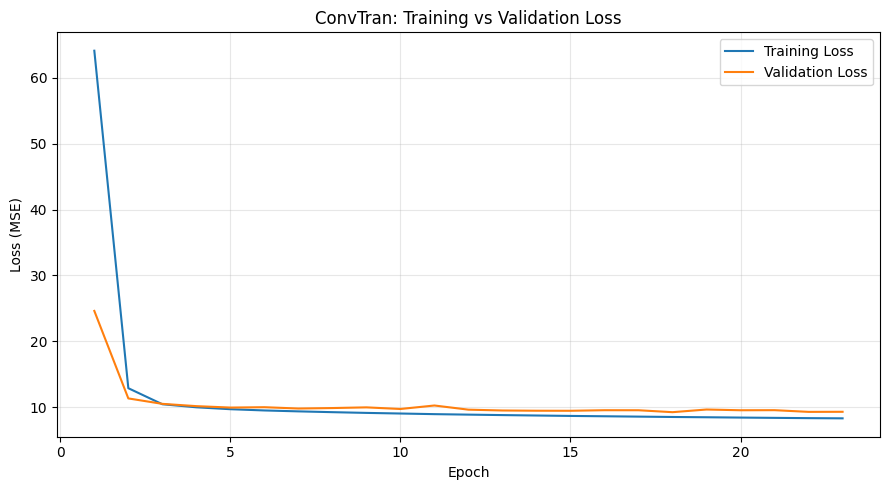

In [19]:
plot_convtran_loss(history)

In [20]:
checkpoint = torch.load(
    './checkpoints/model_best.pth',
    map_location=device
)

model.load_state_dict(checkpoint['state_dict'])
model.to(device)

test_evaluator = SupervisedTrainer(
    model=model,
    dataloader=test_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None,
    print_interval=10,
    console=True,
    print_conf_mat=False
)

In [21]:
test_metrics, test_results = test_evaluator.evaluate(
    epoch_num=None,
    keep_all=True
)

In [22]:
y_true = test_results['targets']
y_pred = test_results['predictions']

print("True shape:", y_true.shape)
print("Pred shape:", y_pred.shape)

True shape: (105176, 2)
Pred shape: (105176, 2)


===== SBP Metrics =====
RMSE: 17.9023
MSE : 320.4914
R²  : 0.3929
MAE : 13.3770


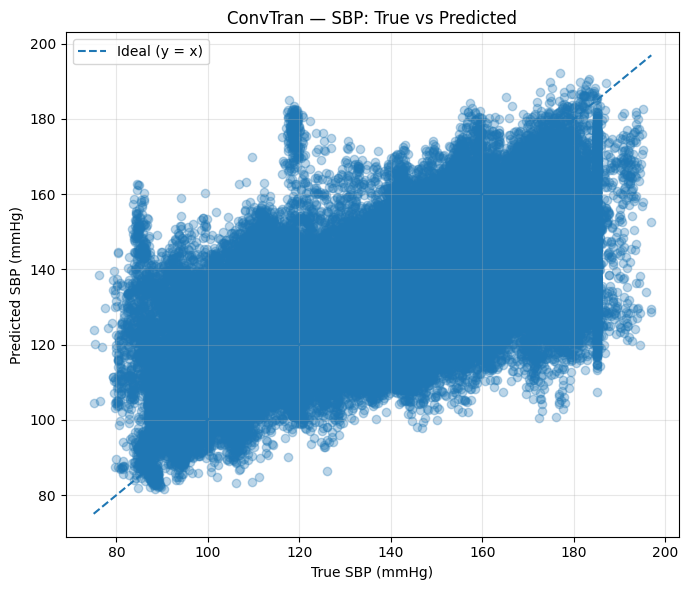

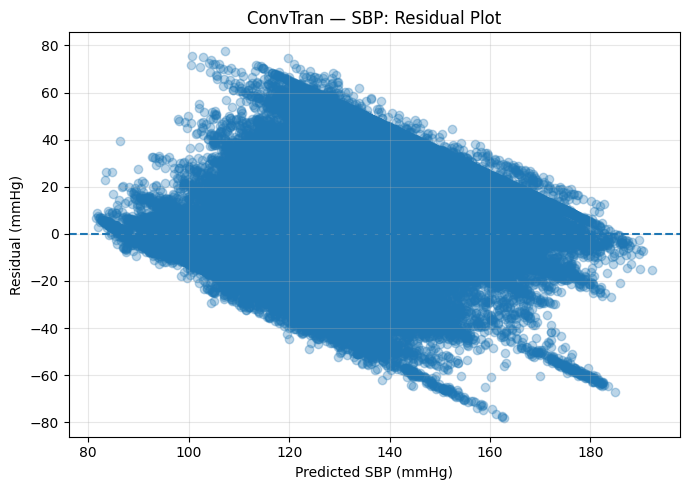

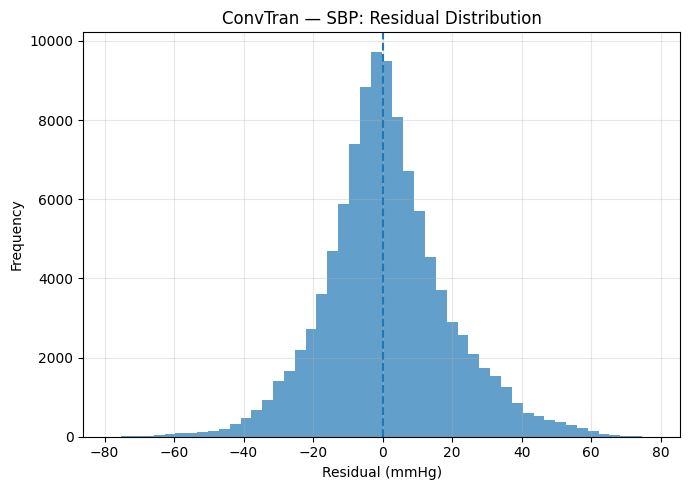

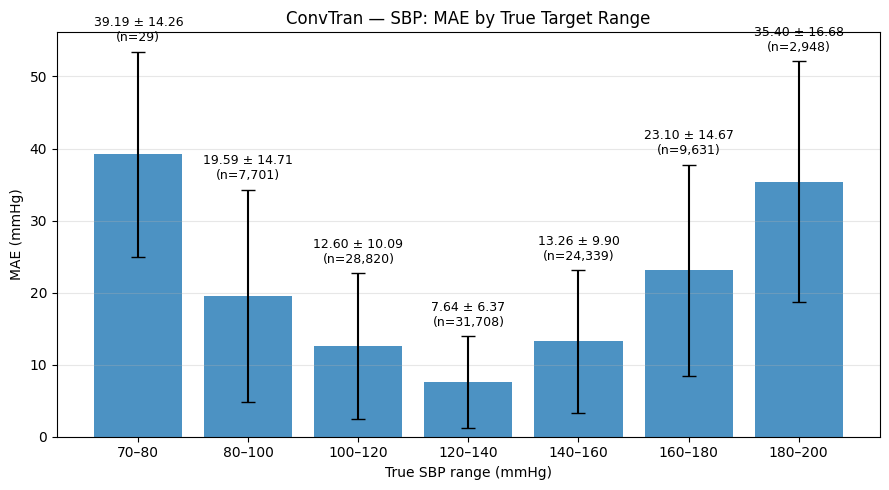

===== DBP Metrics =====
RMSE: 9.3661
MSE : 87.7236
R²  : 0.2992
MAE : 6.8013


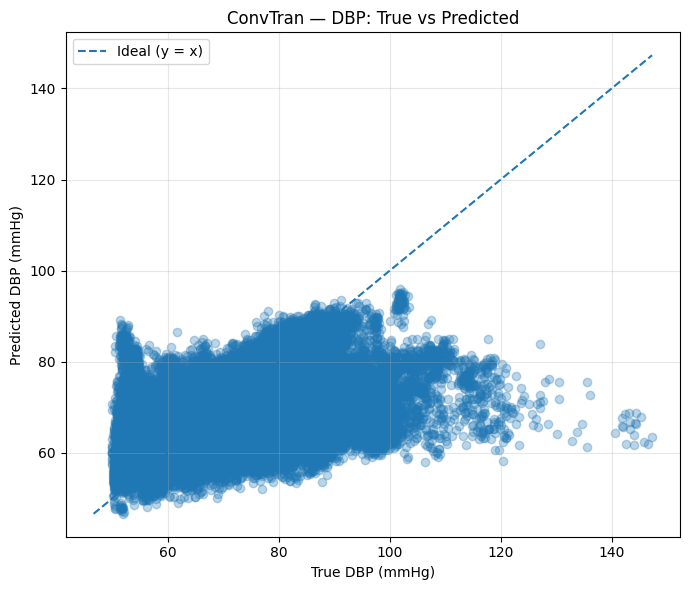

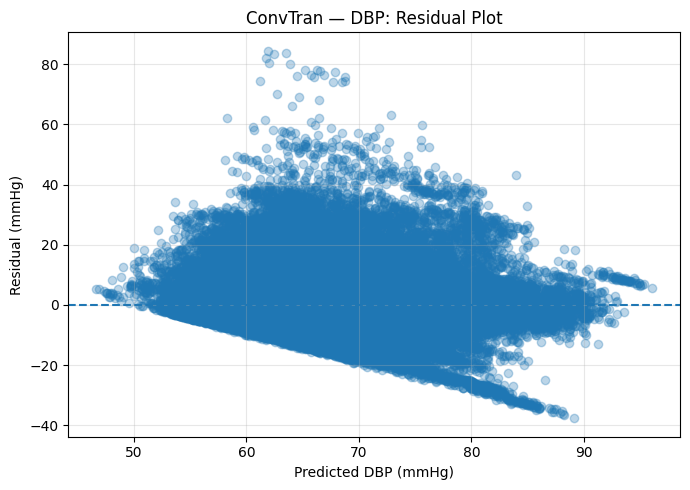

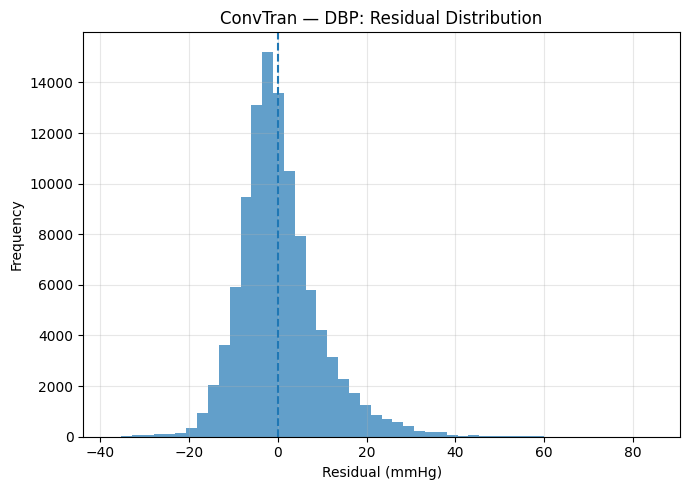

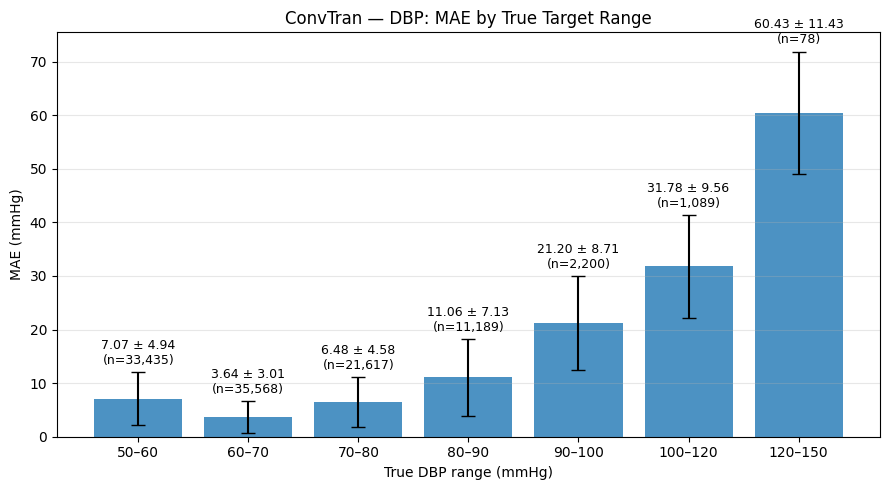

In [23]:
# Convert to NumPy arrays if they are PyTorch tensors
if torch.is_tensor(y_true):
    y_true = y_true.detach().cpu().numpy()

if torch.is_tensor(y_pred):
    y_pred = y_pred.detach().cpu().numpy()

# Extract SBP and DBP separately
sbp_true = y_true[:, 0]
sbp_pred = y_pred[:, 0]

dbp_true = y_true[:, 1]
dbp_pred = y_pred[:, 1]

# SBP metrics and plots
print("===== SBP Metrics =====")
print_metrics(sbp_true, sbp_pred)

plot_regression_results(
    sbp_true,
    sbp_pred,
    model_name="ConvTran",
    target_name="SBP"
)

# DBP metrics and plots
print("===== DBP Metrics =====")
print_metrics(dbp_true, dbp_pred)

plot_regression_results(
    dbp_true,
    dbp_pred,
    model_name="ConvTran",
    target_name="DBP"
)

Number of VitalDB cases: 1963


ConvTran VitalDB prediction: 100%|██████████| 1963/1963 [55:53<00:00,  1.71s/case] 



CONVTRAN
VITALDB ZERO-SHOT RESULTS

SBP
RMSE: 24.1265
MSE : 582.0894
R²  : -0.3619
MAE : 19.3841

DBP
RMSE: 13.0972
MSE : 171.5379
R²  : -0.0562
MAE : 10.3193


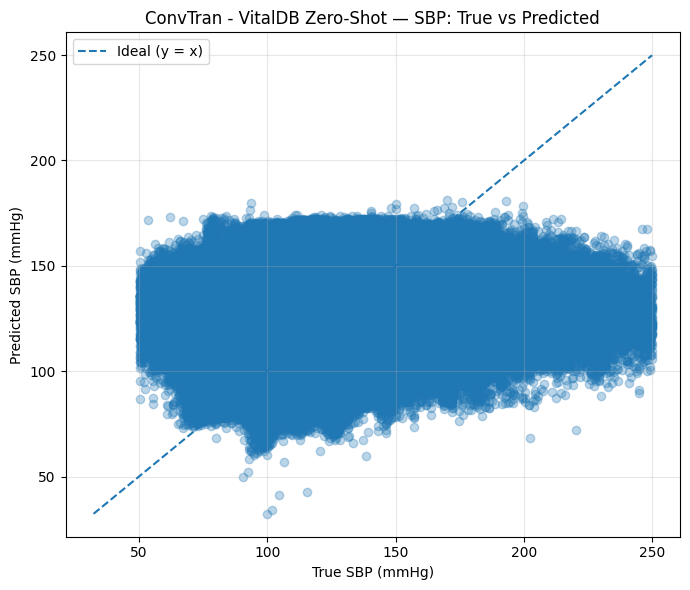

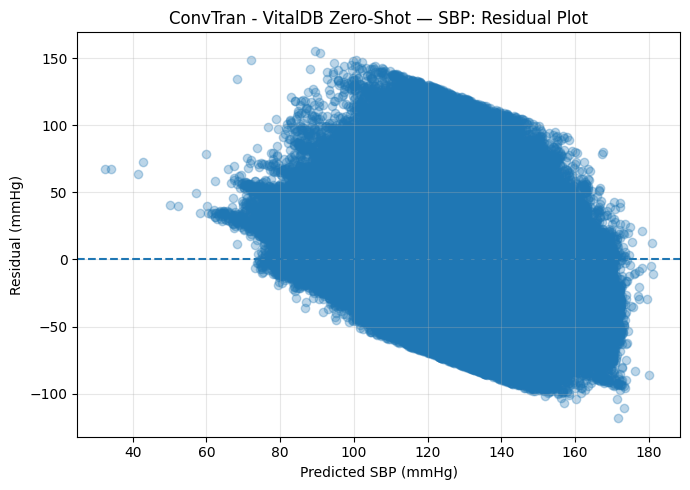

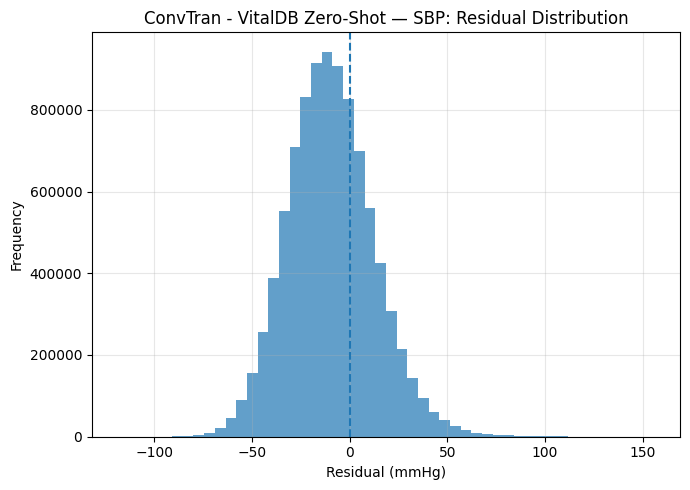

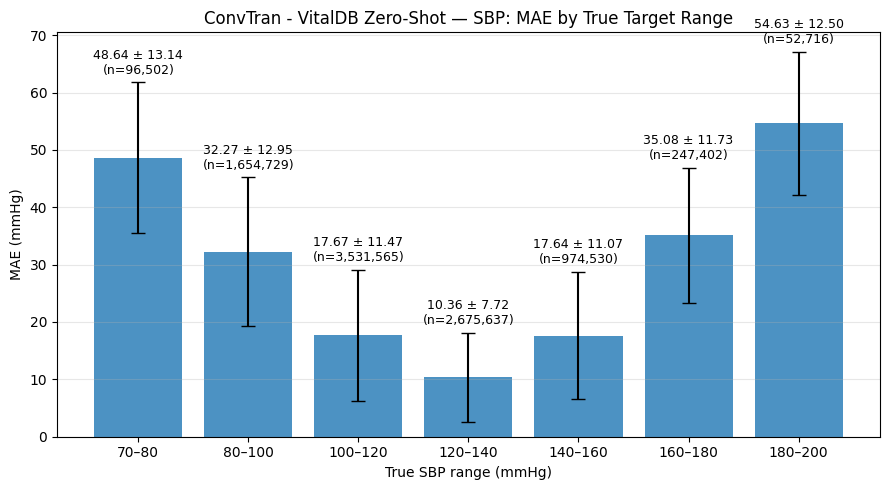

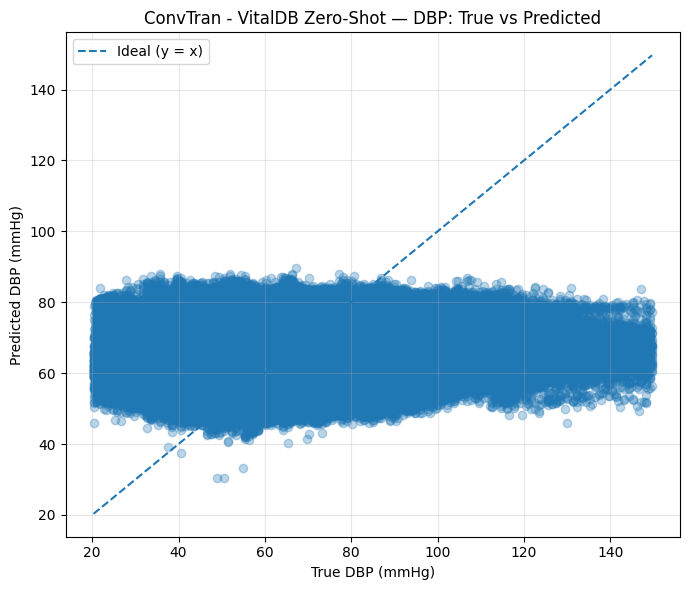

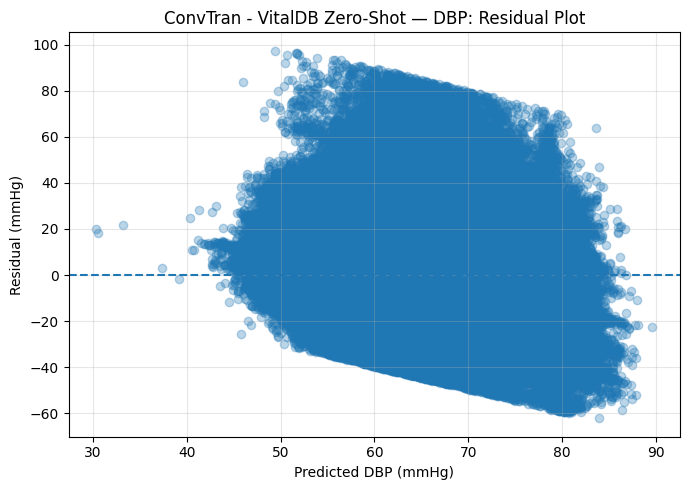

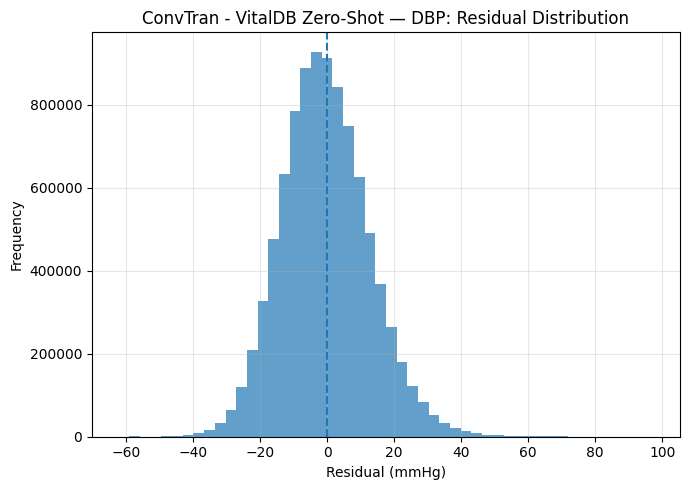

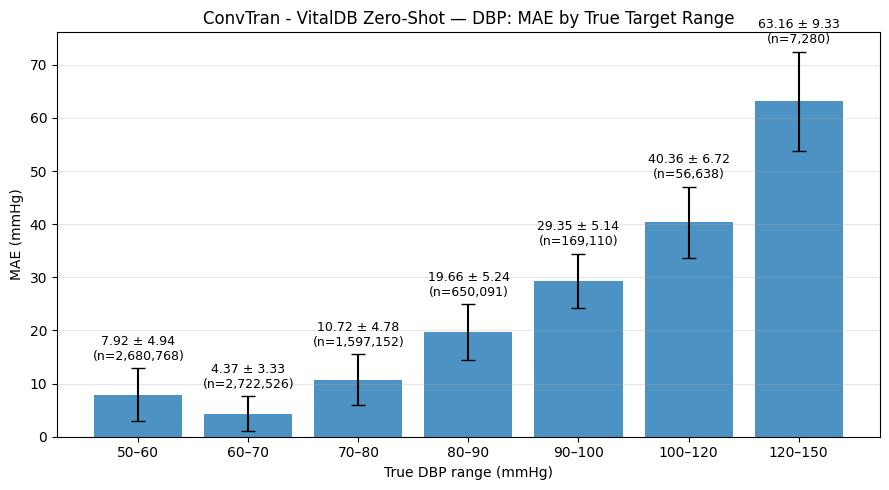

In [24]:
from processing import evaluate_convtran_vitaldb
convtran_vitaldb_results = evaluate_convtran_vitaldb(
    model=model,  # Your trained, best-checkpoint ConvTran model
    base_dir=BASE_DIR,
    batch_size=64,
    device=device
)